# Project 1: Segmenting Wholesale Customers by Spending Behaviour

## Charles MUGANGA B35391

DSC8307 Data Mining, Modeling and Analytics. Advent 2026 Assignment 2.

## What this notebook does

A wholesale distributor in Portugal recorded how much each of its 440 customers spent in a year on six product categories. The distributor would like to understand the different kinds of customers it serves so it can treat them differently. In this notebook I am working through the three tasks set in the assignment:

1. Exploring the data, writing a short report on it, preparing it with a reason for every step, and checking whether the data has any cluster tendency at all.
2. Comparing partitioning (k means), hierarchical (Ward) and density based (DBSCAN and HDBSCAN) clustering on both quality and interpretability.
3. Naming the resulting segments, describing their spending habits and suggesting how each could be served.

The notebook runs from top to bottom with the packages in `requirements.txt` and reads its data from the `data` folder. I am using a single random seed throughout so that the numbers in the text match the outputs.

In [ ]:
# importing the libraries I need for data handling, clustering and plotting
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# fixing one random seed, so that every resample and every clustering run gives the same answer each time
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

## Part 1. Understanding the data

### 1.1 Loading and checking the file

The data comes from the UCI Machine Learning Repository and was originally collected by Abreu (2011). Each row is a customer. Six columns give annual spending in monetary units (m.u.) on fresh food, milk, grocery, frozen goods, detergents and paper, and delicatessen. Two more columns describe the customer: the sales channel and the region. The README does not list the codes, so I am using the coding from the UCI documentation: channel 1 is Horeca (hotels, restaurants and cafés) and 2 is retail, and region 1 is Lisbon, 2 is Oporto and 3 is other regions. The counts below (298 Horeca, 142 retail, 77 Lisbon, 47 Oporto, 316 other) match that documentation exactly.

In [2]:
# Loading the data, checking its shape, and looking for missing values and duplicates
raw = pd.read_csv("data/wholesale-customers.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
print("Rows and columns:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()), "  duplicate rows:", int(raw.duplicated().sum()))
raw.head()

Rows and columns: (440, 8)
Missing values: 0   duplicate rows: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
# Translating the channel and region codes into readable labels for later profiling
df = raw.copy()
df["Channel"] = df["Channel"].map({1: "Horeca", 2: "Retail"})
df["Region"] = df["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Other"})
print(df["Channel"].value_counts().to_string(), "\n")
print(df["Region"].value_counts().to_string())

Channel
Horeca    298
Retail    142 

Region
Other     316
Lisbon     77
Oporto     47


### 1.2 How spending is distributed

In [ ]:
# Summarizing the six spending columns, including how skewed each one is
summary = df[spend_cols].describe().T
summary["skewness"] = df[spend_cols].skew()
summary.round(1)

,count,mean,std,min,25%,50%,75%,max,skewness
Fresh,440.0,12000.3,12647.3,3.0,3127.8,8504.0,16933.8,112151.0,2.6
Milk,440.0,5796.3,7380.4,55.0,1533.0,3627.0,7190.2,73498.0,4.1
Grocery,440.0,7951.3,9503.2,3.0,2153.0,4755.5,10655.8,92780.0,3.6
Frozen,440.0,3071.9,4854.7,25.0,742.2,1526.0,3554.2,60869.0,5.9
Detergents_Paper,440.0,2881.5,4767.9,3.0,256.8,816.5,3922.0,40827.0,3.6
Delicatessen,440.0,1524.9,2820.1,3.0,408.2,965.5,1820.2,47943.0,11.2


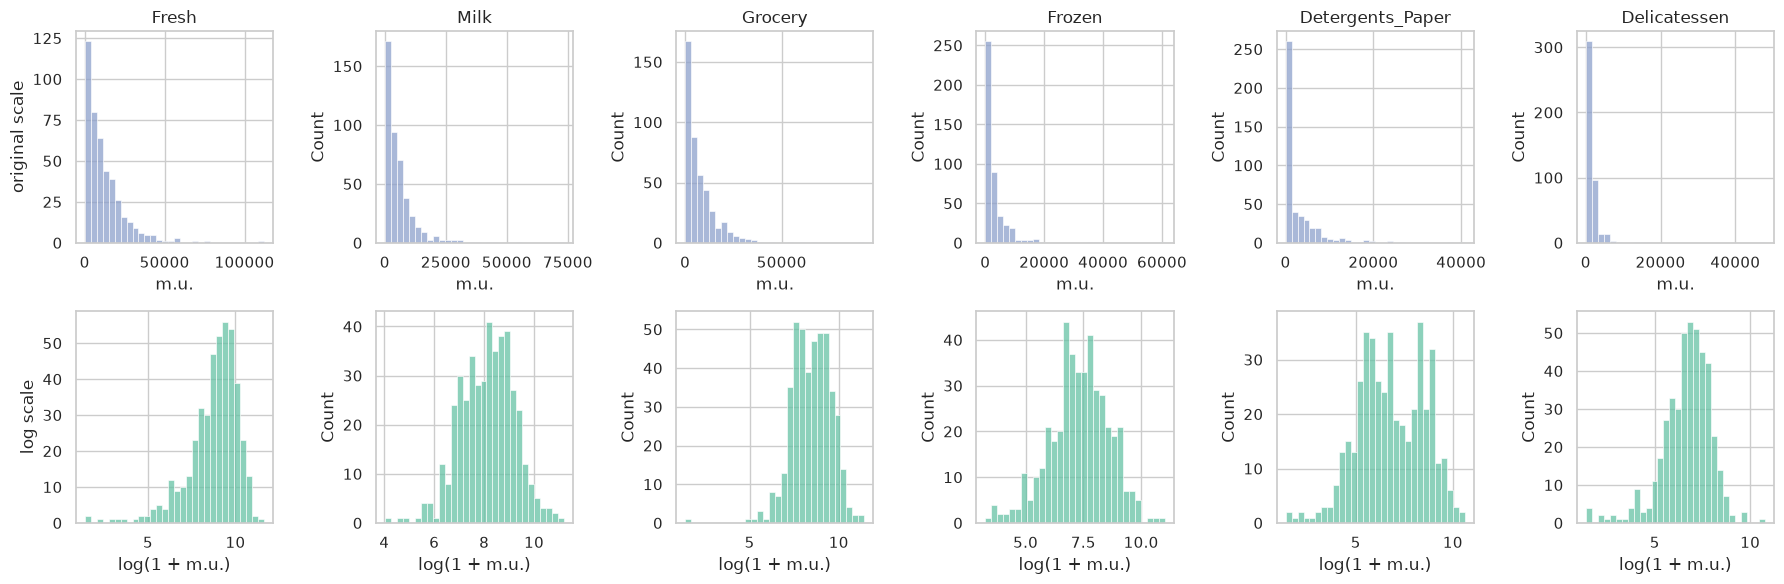

In [5]:
# Comparing each category on its original scale and on a log scale
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for i, col in enumerate(spend_cols):
    sns.histplot(df[col], bins=30, ax=axes[0, i], color="#8da0cb")
    axes[0, i].set_title(col); axes[0, i].set_xlabel("m.u.")
    sns.histplot(np.log1p(df[col]), bins=30, ax=axes[1, i], color="#66c2a5")
    axes[1, i].set_xlabel("log(1 + m.u.)")
axes[0, 0].set_ylabel("original scale"); axes[1, 0].set_ylabel("log scale")
plt.tight_layout(); plt.show()

Every spending category is strongly right skewed. Most customers spend modest amounts, while a small number spend many times more. The skewness ranges from 2.6 for fresh food to 11.2 for delicatessen, where the largest customer spends 47,943 m.u. against a median of 966 m.u. On the original scale, almost all customers are squeezed into the left edge of each histogram.

On a log scale (bottom row) the distributions become roughly symmetric. That matters for clustering. Distance based methods would otherwise be driven almost entirely by the handful of very large accounts, and differences between customers are better described in relative terms anyway. A customer spending 2,000 instead of 1,000 on milk differs from the norm about as much as one spending 20,000 instead of 10,000. A few customers also spend almost nothing in a category, as little as 3 m.u. in some cases, which shows up as the small bumps at the far left of the log histograms.

### 1.3 How the categories relate to each other

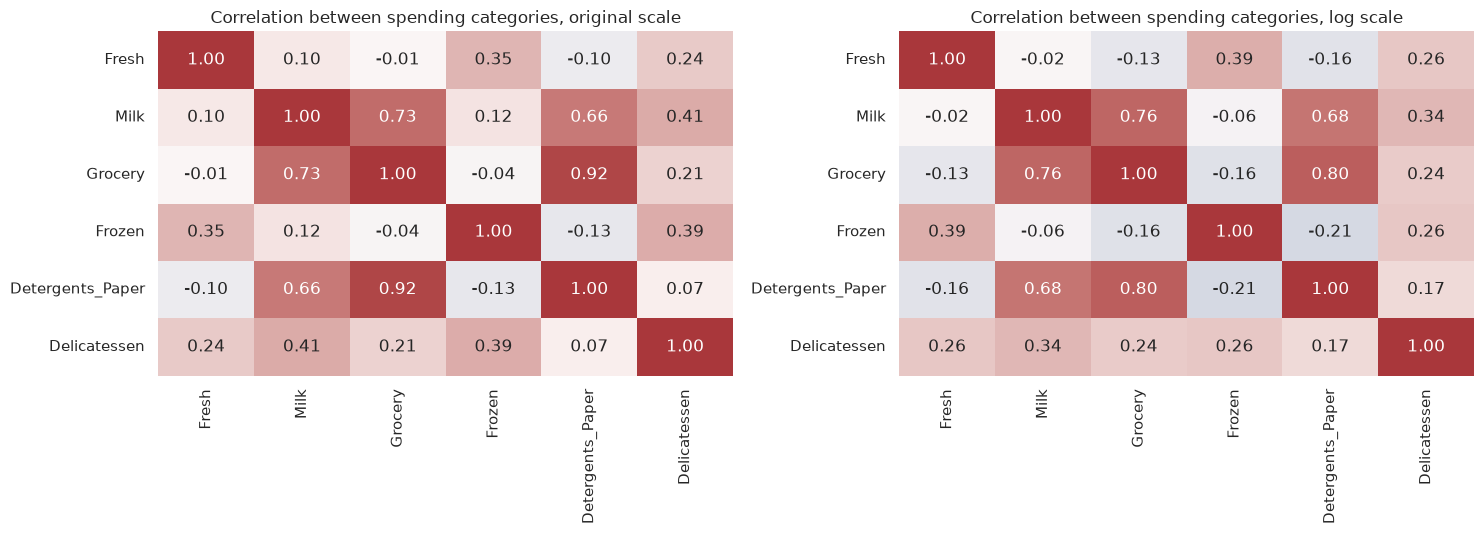

In [6]:
# Checking correlations on the original and on the log scale side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (title, data) in zip(axes, [("original scale", df[spend_cols]), ("log scale", np.log1p(df[spend_cols]))]):
    sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar=False)
    ax.set_title(f"Correlation between spending categories, {title}")
plt.tight_layout(); plt.show()

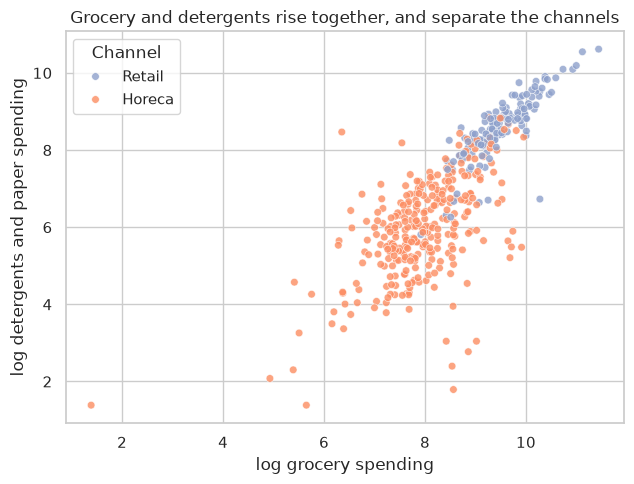

In [7]:
# Plotting the strongest relationship, grocery against detergents and paper, coloured by channel
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(data=df, x=np.log1p(df["Grocery"]), y=np.log1p(df["Detergents_Paper"]), hue="Channel",
                palette={"Horeca": "#fc8d62", "Retail": "#8da0cb"}, s=30, alpha=0.8, ax=ax)
ax.set(xlabel="log grocery spending", ylabel="log detergents and paper spending",
       title="Grocery and detergents rise together, and separate the channels")
plt.tight_layout(); plt.show()

Two families of categories stand out. Grocery, detergents and paper, and milk move together strongly (for example grocery and detergents correlate at 0.92 on the original scale and 0.80 on the log scale). These are the packaged, shelf stable goods a shop sells on. Fresh food and frozen goods form a second, looser family (0.39 on the log scale) and are almost unrelated to the first group. Delicatessen has mild links with everything.

The scatter plot shows that the grocery and detergent axis also separates the two sales channels quite well: retailers sit in the upper right and Horeca customers in the lower left, with a fair amount of overlap. I expect any clustering to pick up this axis.

### 1.4 Spending by channel and region

In [8]:
# Comparing median spending across channels and regions
by_channel = df.groupby("Channel")[spend_cols].median()
by_region = df.groupby("Region")[spend_cols].median()
print("Median spending by channel"); print(by_channel.round(0))
print("\nMedian spending by region"); print(by_region.round(0))

Median spending by channel
          Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Channel                                                                 
Horeca   9582.0  2157.0   2684.0  2058.0             386.0         821.0
Retail   5994.0  7812.0  12390.0  1081.0            5614.0        1350.0

Median spending by region
         Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
Region                                                                 
Lisbon  7363.0  3748.0   3838.0  1801.0             737.0         806.0
Oporto  8090.0  2374.0   6114.0  1455.0             811.0         898.0
Other   8752.0  3684.0   4732.0  1498.0             856.0         994.0


The channel makes a large difference. A typical retailer spends about 4.6 times as much on grocery and about 15 times as much on detergents and paper as a typical Horeca customer, while Horeca customers spend more on fresh and frozen food. The regions, by contrast, look very similar. This suggests that what a customer is (a shop or a kitchen) shapes their spending far more than where they are.

### 1.5 Unusual customers

In [9]:
# Counting customers who are extreme in at least one category once spending is on a log scale
log_spend = np.log1p(df[spend_cols])
z = (log_spend - log_spend.mean()) / log_spend.std()
extreme = (z.abs() > 3).any(axis=1)
print("Customers more than 3 standard deviations from the mean in at least one category (log scale):", int(extreme.sum()))
print("\nWhich categories make them extreme:")
print((z.abs() > 3).sum().to_string())
df.loc[extreme, ["Channel", "Region"] + spend_cols].head(10)

Customers more than 3 standard deviations from the mean in at least one category (log scale): 18

Which categories make them extreme:
Fresh               6
Milk                2
Grocery             2
Frozen              1
Detergents_Paper    2
Delicatessen        8


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
66,Horeca,Other,9,1534,7417,175,3468,27
75,Horeca,Other,20398,1137,3,4407,3,975
95,Horeca,Other,3,2920,6252,440,223,709
96,Retail,Other,23,2616,8118,145,3874,217
98,Horeca,Other,503,112,778,895,56,132
109,Retail,Other,1406,16729,28986,673,836,3
128,Horeca,Other,140,8847,3823,142,1062,3
142,Horeca,Other,37036,7152,8253,2995,20,3
154,Horeca,Other,622,55,137,75,7,8
161,Horeca,Other,12434,540,283,1092,3,2233


On the log scale, 18 customers are more than three standard deviations from the average in at least one category. Almost all of them are unusual because they spend very little in a category (for example 3 m.u. on fresh food or delicatessen), not because they spend a lot. Such tiny values may be genuine (a café that buys no detergents through this distributor) or may reflect accounts that mostly buy elsewhere. Nothing in the data marks them as errors, so I am keeping them and checking later whether removing them changes the segments.

### 1.6 Short report on the data

The dataset holds 440 customers with six annual spending figures and two descriptive codes. There are no missing values and no duplicate rows. Two thirds of customers are Horeca businesses and one third are retailers, and 72 percent come from outside Lisbon and Oporto.

The main limitations are these. Spending is extremely right skewed, so raw values would let a few very large accounts dominate any distance based method. A small number of customers record near zero spending in some categories, which may reflect buying from other suppliers rather than a lack of need, since we only see each customer's spending with this one distributor. The data covers a single year, so seasonal or changing behaviour is invisible. Spending is in monetary units with no information on prices, margins or number of orders, so we cannot tell volume from value or how often customers order. Finally, the region variable is coarse (more than two thirds of customers fall into "other").

The exploration points to one dominant pattern, a packaged goods axis (grocery, detergents and paper, milk) that largely separates retailers from Horeca businesses, and a weaker fresh and frozen axis.

## Data preparation

1. I am clustering on the six spending columns only. The task asks for segments based on spending behaviour, so channel and region are left out of the clustering and kept aside to describe and check the segments afterwards. Using channel as an input would also make the comparison with channel circular.
2. I am applying a log transform, log(1 + spending). This removes most of the skew, stops a few large accounts from dominating the distances, and means that clusters reflect the pattern of a customer's basket in relative terms. Adding one before taking the log keeps the very small values finite. This transform is standard for this dataset in the literature on customer segmentation.
3. I am standardising each log transformed column to mean zero and standard deviation one, so that every category carries equal weight in the distances. Without this, categories with a wider spread would count for more simply because of their units.
4. I am keeping all 440 customers, including the 18 unusual ones. Section 2.5 checks how much the segments change if they are removed.

In [10]:
# Building the feature matrix: log transform, then standardise each column
X_log = np.log1p(df[spend_cols])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
print("Feature matrix:", X.shape)
pd.DataFrame(X, columns=spend_cols).describe().round(2)

Feature matrix: (440, 6)


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,0.00,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-5.00,-3.79,-6.36,-3.16,-3.17,-4.09
25%,-0.47,-0.73,-0.69,-0.54,-0.73,-0.51
50%,0.21,0.07,0.02,0.02,-0.05,0.16
75%,0.68,0.70,0.75,0.68,0.87,0.65
max,1.97,2.86,2.70,2.90,2.24,3.18


### 1.7 Does the data have a cluster tendency?

Before clustering it is worth asking whether there are any groups to find at all, because a clustering algorithm will happily split even completely structureless data. I am using the Hopkins statistic (Hopkins and Skellam, 1954, in the form described by Lawson and Jurs, 1990). It compares the distance from randomly chosen real customers to their nearest neighbour with the distance from randomly placed artificial points to their nearest real customer. If the data is spread evenly, the two are similar and H is about 0.5. If the data is clumped, the artificial points land in empty space far from any customer and H moves towards 1.

A single value of H can be misleading, so I am repeating the calculation 200 times and comparing it with two reference cases. The first is uniform random data, the textbook reference. The second is a stricter one: data drawn from a single multivariate normal blob with the same means and correlations as our customers. A single blob has no clusters, yet it is not uniform either, so it also scores above 0.5. Only if our data scores clearly above this blob can we say there is genuine group structure.

In [11]:
def hopkins(data, rng, sample_frac=0.1):
    """Calculating one Hopkins statistic: values near 0.5 mean no structure, values near 1 mean strong clustering."""
    n, d = data.shape
    m = int(sample_frac * n)
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    real = data[rng.choice(n, m, replace=False)]
    w_dist = nn.kneighbors(real)[0][:, 1]                       # nearest other real customer
    fake = rng.uniform(data.min(axis=0), data.max(axis=0), (m, d))
    u_dist = nn.kneighbors(fake, n_neighbors=1)[0][:, 0]        # nearest real customer to an artificial point
    return u_dist.sum() / (u_dist.sum() + w_dist.sum())

# Repeating the statistic 200 times for the real data and for the two reference cases
h_data = [hopkins(X, rng) for _ in range(200)]
h_uniform = [hopkins(rng.uniform(size=X.shape), rng) for _ in range(200)]
h_blob = [hopkins(StandardScaler().fit_transform(rng.multivariate_normal(X.mean(0), np.cov(X.T), len(X))), rng)
          for _ in range(200)]

tendency = pd.DataFrame({
    "mean H": [np.mean(h_data), np.mean(h_blob), np.mean(h_uniform)],
    "2.5%": [np.percentile(v, 2.5) for v in (h_data, h_blob, h_uniform)],
    "97.5%": [np.percentile(v, 97.5) for v in (h_data, h_blob, h_uniform)],
}, index=["customers (log scale)", "single normal blob (same correlations)", "uniform random data"])
tendency.round(3)

,mean H,2.5%,97.5%
customers (log scale),0.798,0.768,0.826
single normal blob (same correlations),0.730,0.694,0.770
uniform random data,0.500,0.477,0.525


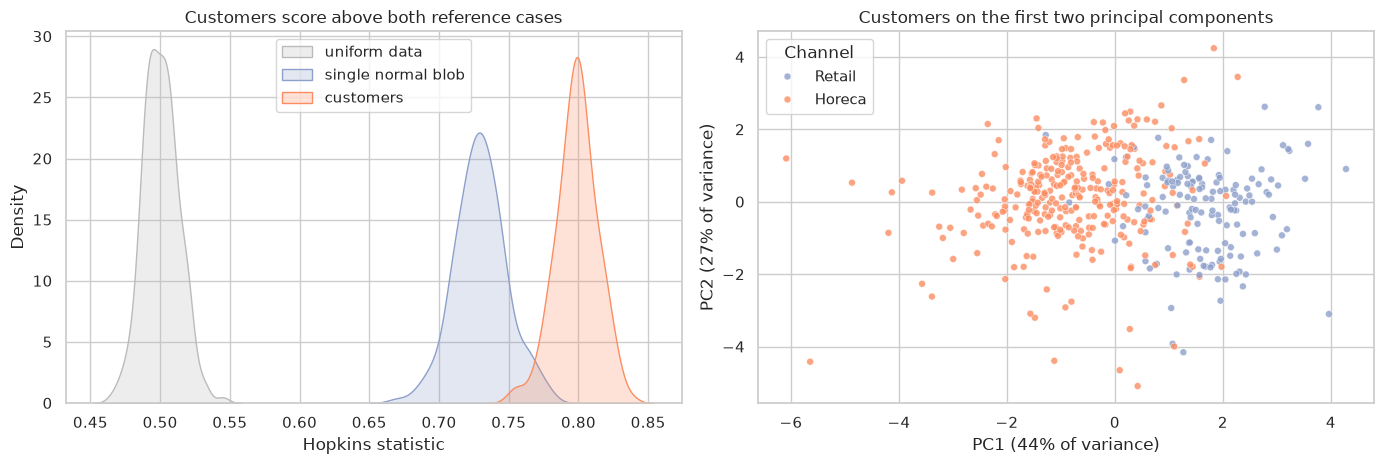

In [12]:
# Plotting the three distributions of H, and a two dimensional view of the customers
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for vals, lab, col in [(h_uniform, "uniform data", "#bbbbbb"), (h_blob, "single normal blob", "#8da0cb"), (h_data, "customers", "#fc8d62")]:
    sns.kdeplot(vals, ax=axes[0], fill=True, label=lab, color=col)
axes[0].set(xlabel="Hopkins statistic", title="Customers score above both reference cases")
axes[0].legend()
pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pcs.transform(X)
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["Channel"], palette={"Horeca": "#fc8d62", "Retail": "#8da0cb"},
                s=25, alpha=0.8, ax=axes[1])
axes[1].set(xlabel=f"PC1 ({pcs.explained_variance_ratio_[0]:.0%} of variance)",
            ylabel=f"PC2 ({pcs.explained_variance_ratio_[1]:.0%} of variance)",
            title="Customers on the first two principal components")
plt.tight_layout(); plt.show()

The customers score about 0.80, clearly above uniform data (0.50) and also above a single normal blob with the same correlations (about 0.73). The intervals from the repeated runs do not overlap. So the data does have genuine cluster tendency, but it is moderate rather than strong. Much of the apparent clumping simply comes from the categories being correlated, and only the extra margin above the blob reflects real grouping.

The principal component view tells the same story. The first component, which is essentially the packaged goods axis, spreads customers along a continuum with denser areas at each end, roughly matching the two channels, and no clean gap between them. I therefore expect clustering to find a small number of overlapping groups rather than sharply separated ones, and I will be careful not to over interpret fine splits.

## Part 2. Comparing three families of clustering

I am comparing one method from each of the three families named in the task:

1. Partitioning: k means (MacQueen, 1967), which places k centres and assigns each customer to the nearest one. It works well for compact, roughly round groups and gives a simple "typical customer" for each segment.
2. Hierarchical: agglomerative clustering with Ward linkage (Ward, 1963), which starts with every customer on its own and repeatedly merges the two groups whose merger increases the within group variance least. It produces a full tree, so the number of segments can be chosen afterwards.
3. Density based: DBSCAN (Ester and colleagues, 1996) and its hierarchical extension HDBSCAN (Campello, Moulavi and Sander, 2013). These look for dense regions separated by sparse ones and can label customers who belong to no dense region as noise.

For quality I am using the silhouette coefficient (Rousseeuw, 1987, higher is better, from minus 1 to 1), the Davies Bouldin index (lower is better) and the Calinski Harabasz index (higher is better). For robustness I am measuring how stable the clusters are when the customers are resampled (Hennig, 2007). For interpretability I am looking at how distinct and describable the cluster profiles are, and how they relate to the channel variable that was left out of the clustering.

### 2.1 Partitioning: k means

In [13]:
# Running k means for 2 to 8 clusters and recording the internal quality measures for each
def internal_scores(data, labels):
    return {"silhouette": silhouette_score(data, labels),
            "Davies Bouldin": davies_bouldin_score(data, labels),
            "Calinski Harabasz": calinski_harabasz_score(data, labels)}

km_rows, km_models = [], {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X)
    km_models[k] = km
    km_rows.append({"k": k, "within cluster sum of squares": km.inertia_,
                    **internal_scores(X, km.labels_), "cluster sizes": np.bincount(km.labels_).tolist()})
km_table = pd.DataFrame(km_rows).set_index("k")
km_table.round(3)

,within cluster sum of squares,silhouette,Davies Bouldin,Calinski Harabasz,cluster sizes
k,,,,,
2,1844.064,0.290,1.352,189.050,"[252, 188]"
3,1553.340,0.259,1.344,152.855,"[81, 212, 147]"
4,1386.823,0.189,1.541,131.328,"[61, 130, 131, 118]"
5,1266.149,0.192,1.484,118.000,"[90, 96, 54, 100, 100]"
6,1174.204,0.197,1.464,108.355,"[49, 56, 23, 97, 114, 101]"
7,1086.359,0.196,1.392,103.208,"[20, 41, 48, 89, 84, 118, 40]"
8,1022.189,0.192,1.397,97.675,"[107, 90, 24, 32, 45, 45, 86, 11]"


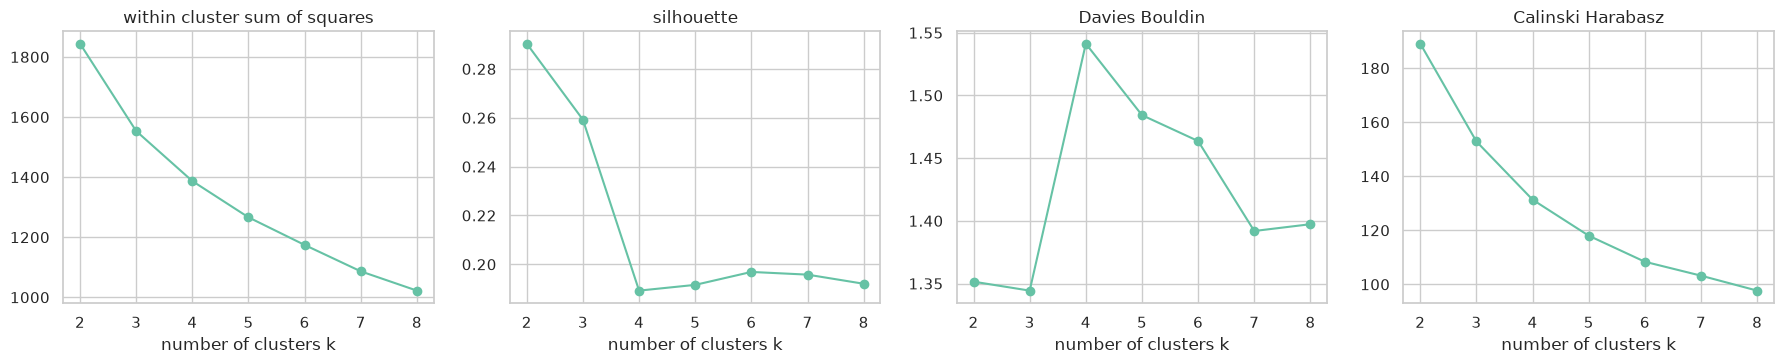

In [14]:
# Plotting the elbow and the quality measures against k
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, ["within cluster sum of squares", "silhouette", "Davies Bouldin", "Calinski Harabasz"]):
    ax.plot(km_table.index, km_table[col], marker="o", color="#66c2a5")
    ax.set(title=col, xlabel="number of clusters k")
plt.tight_layout(); plt.show()

Every measure points to a small number of clusters. The silhouette is highest at k = 2 (0.29) with k = 3 close behind (0.26), and then drops to about 0.19 to 0.20 for four or more clusters. The Calinski Harabasz index falls steadily from k = 2, and Davies Bouldin is lowest at k = 2 and 3. The elbow curve has no sharp bend, which is typical of data that forms a continuum. A silhouette below 0.3 is usually read as weak structure, which agrees with the moderate Hopkins result.

In [15]:
# Measuring stability: refitting k means on 100 bootstrap samples and checking how well each
# original cluster is recovered, using the Jaccard similarity of Hennig (2007)
def stability(data, k, n_boot=100):
    base = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(data).labels_
    ari, jac = [], {c: [] for c in range(k)}
    for b in range(n_boot):
        idx = rng.choice(len(data), len(data), replace=True)
        model = KMeans(n_clusters=k, n_init=10, random_state=b).fit(data[idx])
        ari.append(adjusted_rand_score(base, model.predict(data)))
        uniq = np.unique(idx)
        lab_b = model.predict(data[uniq])
        for c in range(k):
            A = set(np.where(base[uniq] == c)[0])
            jac[c].append(max(len(A & set(np.where(lab_b == j)[0])) / len(A | set(np.where(lab_b == j)[0]))
                              for j in range(k)))
    return np.mean(ari), np.percentile(ari, 5), [np.mean(v) for v in jac.values()]

stab_rows = []
for k in range(2, 6):
    mean_ari, low_ari, jac = stability(X, k)
    stab_rows.append({"k": k, "mean ARI with full data solution": mean_ari, "5th percentile ARI": low_ari,
                      "Jaccard per cluster": np.round(jac, 2).tolist(), "lowest cluster Jaccard": min(jac)})
stab_table = pd.DataFrame(stab_rows).set_index("k")
stab_table.round(3)

,mean ARI with full data solution,5th percentile ARI,Jaccard per cluster,lowest cluster Jaccard
k,,,,
2,0.905,0.654,"[0.96, 0.95]",0.949
3,0.752,0.357,"[0.77, 0.88, 0.73]",0.726
4,0.639,0.364,"[0.69, 0.66, 0.7, 0.78]",0.664
5,0.568,0.312,"[0.6, 0.53, 0.71, 0.77, 0.64]",0.533


Stability tells a clearer story than the silhouette. With two clusters, a bootstrap solution agrees with the full data solution very closely (mean adjusted Rand index about 0.90, and both clusters have a Jaccard similarity of about 0.97). With three clusters agreement drops but is still reasonable (mean ARI about 0.75). Two of the three clusters have a Jaccard similarity above the 0.75 level that Hennig (2007) suggests for treating a cluster as stable (0.77 and 0.88), and the third sits just below it at 0.73. From four clusters onward several clusters fall below that level, so the extra splits are not reproducible.

So k means supports either two or three segments. Two is clearly the most robust. Three costs only a little in silhouette and is moderately stable, with one cluster that is less certain, and as Part 3 shows it adds a distinction that matters for the business. I am carrying both forward.

### 2.2 Hierarchical: agglomerative clustering

In [16]:
# Comparing linkage methods by how faithfully the tree preserves the original distances (cophenetic correlation)
dist = pdist(X)
coph = {m: cophenet(linkage(X, method=m), dist)[0] for m in ["ward", "average", "complete", "single"]}
pd.Series(coph, name="cophenetic correlation").round(3).to_frame()

,cophenetic correlation
ward,0.484
average,0.745
complete,0.654
single,0.649


Average linkage preserves the original distances best (cophenetic correlation 0.75) and Ward the least (0.48). That needs interpreting carefully. A high cophenetic correlation means the tree is a faithful summary of all pairwise distances, but average and single linkage tend to achieve this by peeling off a few outlying customers one by one and leaving one giant cluster, which is not useful for segmentation. The next cell shows this directly.

In [17]:
# Checking what each linkage produces when the tree is cut into two or three clusters
link_rows = []
for m in ["ward", "average", "complete", "single"]:
    for k in [2, 3]:
        lab = AgglomerativeClustering(n_clusters=k, linkage=m).fit_predict(X)
        link_rows.append({"linkage": m, "k": k, "cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True),
                          "silhouette": silhouette_score(X, lab)})
pd.DataFrame(link_rows).round(3)

,linkage,k,cluster sizes,silhouette
0,ward,2,"[262, 178]",0.258
1,ward,3,"[262, 125, 53]",0.255
2,average,2,"[438, 2]",0.569
3,average,3,"[438, 1, 1]",0.542
4,complete,2,"[402, 38]",0.322
5,complete,3,"[402, 33, 5]",0.298
6,single,2,"[439, 1]",0.570
7,single,3,"[438, 1, 1]",0.506


As expected, average and single linkage put almost every customer into one cluster and split off one or a handful of outliers. The silhouette can still look acceptable for such a split, but a "segment" of one customer is of no use to the distributor. Complete linkage is also unbalanced. Ward linkage is the only one that produces groups of a useful size, and it shares the same goal as k means (small within group variance), so I am using Ward for the comparison.

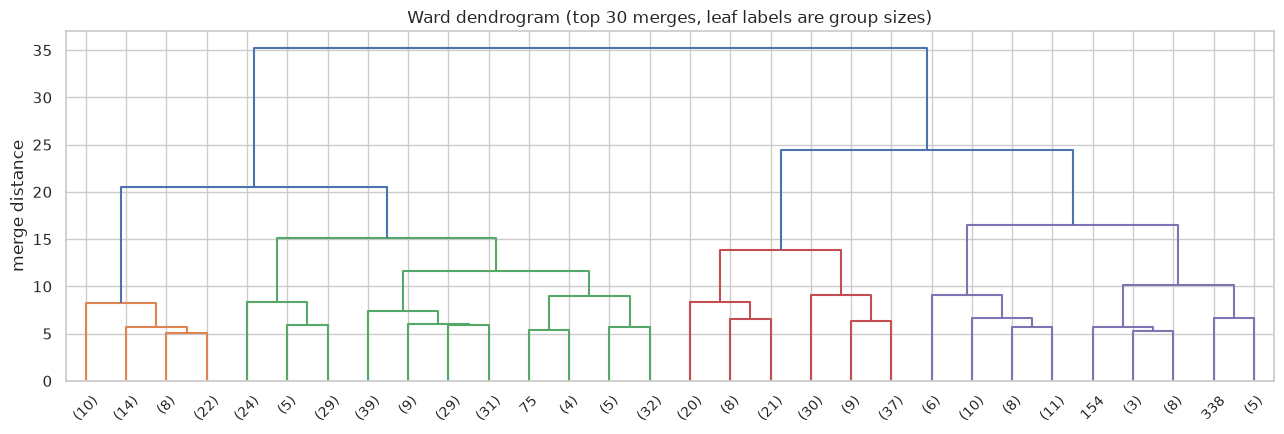

In [18]:
# Drawing the Ward dendrogram, showing only the top of the tree for readability
Z_ward = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(13, 4.5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, ax=ax, color_threshold=Z_ward[-3, 2], show_leaf_counts=True)
ax.set(title="Ward dendrogram (top 30 merges, leaf labels are group sizes)", ylabel="merge distance")
plt.tight_layout(); plt.show()

In [19]:
# Recording Ward's quality measures for 2 to 6 clusters and how far it agrees with k means
ward_rows = []
for k in range(2, 7):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    ward_rows.append({"k": k, **internal_scores(X, lab), "cluster sizes": np.bincount(lab).tolist(),
                      "agreement with k means (ARI)": adjusted_rand_score(km_models[k].labels_, lab)})
pd.DataFrame(ward_rows).set_index("k").round(3)

,silhouette,Davies Bouldin,Calinski Harabasz,cluster sizes,agreement with k means (ARI)
k,,,,,
2,0.258,1.600,134.624,"[178, 262]",0.639
3,0.255,1.539,116.799,"[262, 53, 125]",0.444
4,0.202,1.521,108.607,"[53, 208, 125, 54]",0.395
5,0.203,1.386,100.015,"[208, 18, 125, 54, 35]",0.368
6,0.171,1.490,94.857,"[125, 18, 150, 54, 35, 58]",0.379


The dendrogram shows one very large merge at the top, joining two main branches, and much smaller jumps below it. This is the hierarchical method's way of saying that two groups is the most natural cut. At two and three clusters Ward's silhouette is a little lower than k means (0.26 against 0.29 and 0.26), which is expected because k means directly optimises compactness for a given k, while Ward's merges cannot be undone once made. At four or more clusters both methods sit around 0.17 to 0.20.

At k = 2 the two methods agree well (ARI about 0.64). At k = 3 they agree less (about 0.44) because they split the larger group differently. The cross tabulation below shows where.

In [20]:
# Cross tabulating k means and Ward at three clusters, and comparing their profiles
km3 = km_models[3].labels_
ward3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
print(pd.crosstab(pd.Series(km3, name="k means cluster"), pd.Series(ward3, name="Ward cluster")))
print("\nWard median spending at three clusters")
print(df[spend_cols].groupby(ward3).median().assign(customers=np.bincount(ward3)).round(0))

Ward cluster       0   1   2
k means cluster             
0                 11  36  34
1                201  11   0
2                 50   6  91

Ward median spending at three clusters
     Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicatessen  customers
0  11113.0  2028.0   2584.0  2382.0             358.0         864.0        262
1   1689.0  4230.0   7854.0   661.0            2970.0         156.0         53
2   5981.0  8259.0  12469.0  1148.0            5618.0        1682.0        125


Both methods find the same large fresh food group (k means cluster 1 and Ward cluster 0 share 201 customers). They differ in how they split the remaining packaged goods customers. Ward separates a small group of 53 that spend little on fresh food and delicatessen, while k means separates a group of 81 defined mainly by very low fresh spending. The underlying idea, that some packaged goods customers buy almost no fresh food, appears in both, but the boundary is fuzzy. That is consistent with the continuum seen in Part 1.

### 2.3 Density based: DBSCAN and HDBSCAN

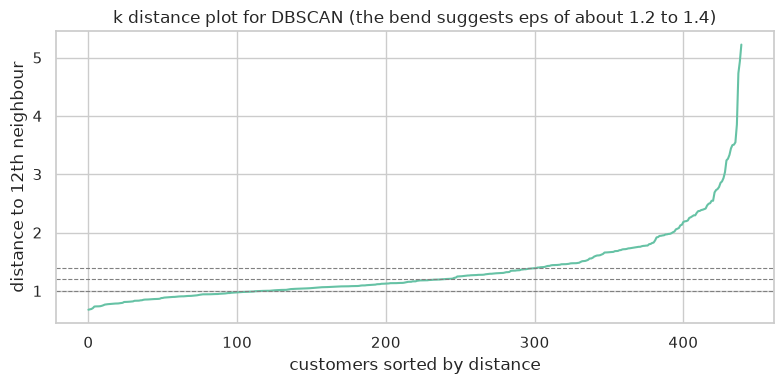

In [21]:
# Choosing DBSCAN's neighbourhood size with a k distance plot: sorted distance from each customer
# to its 12th nearest neighbour (min_samples = 2 x number of features, a common rule of thumb)
min_samples = 2 * X.shape[1]
kdist = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kdist, color="#66c2a5")
for e in [1.0, 1.2, 1.4]:
    ax.axhline(e, ls="--", c="grey", lw=0.8)
ax.set(xlabel="customers sorted by distance", ylabel=f"distance to {min_samples}th neighbour",
       title="k distance plot for DBSCAN (the bend suggests eps of about 1.2 to 1.4)")
plt.tight_layout(); plt.show()

In [22]:
# Trying a range of neighbourhood sizes around the bend in the plot
db_rows = []
for eps in [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.6]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    clusters = sorted([int(c) for c in np.bincount(lab[lab >= 0])], reverse=True) if (lab >= 0).any() else []
    db_rows.append({"eps": eps, "clusters found": len(clusters), "cluster sizes": clusters,
                    "noise customers": int((lab == -1).sum()), "noise share": (lab == -1).mean()})
pd.DataFrame(db_rows).round(3)

,eps,clusters found,cluster sizes,noise customers,noise share
0,0.8,2,"[50, 44]",346,0.786
1,0.9,2,"[89, 78]",273,0.620
2,1.0,1,[257],183,0.416
3,1.1,1,[300],140,0.318
4,1.2,1,[335],105,0.239
5,1.3,1,[361],79,0.180
6,1.4,1,[373],67,0.152
7,1.6,1,[398],42,0.095


In [23]:
# Trying HDBSCAN, which does not need eps, across several minimum cluster sizes
hdb_rows = []
for mcs in [5, 10, 15, 20, 30, 40]:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(X)
    clusters = sorted([int(c) for c in np.bincount(lab[lab >= 0])], reverse=True) if (lab >= 0).any() else []
    hdb_rows.append({"min cluster size": mcs, "clusters found": len(clusters), "cluster sizes": clusters,
                     "noise share": (lab == -1).mean()})
pd.DataFrame(hdb_rows).round(3)

,min cluster size,clusters found,cluster sizes,noise share
0,5,2,"[236, 6]",0.450
1,10,2,"[56, 44]",0.773
2,15,2,"[36, 36]",0.836
3,20,2,"[37, 36]",0.834
4,30,2,"[42, 37]",0.820
5,40,0,[],1.000


The density based methods behave very differently from the other two, and the difference is informative.

DBSCAN never finds more than one sizeable dense region. Around the bend in the k distance plot (eps of 1.2 to 1.4) it finds a single dense core containing 76 to 85 percent of customers and calls the rest noise. Only at the smallest settings (eps of 0.8 and 0.9) does it find two groups, and then it labels 62 to 79 percent of customers as noise.

HDBSCAN, which adapts to varying density, does no better. With the smallest setting it finds one large cluster of 236 customers plus a tiny one of 6, leaving 45 percent as noise. With larger settings it finds two small clusters of 36 to 56 customers and leaves 77 to 84 percent as noise, and at a minimum size of 40 it labels everyone as noise.

The reason is that there are no low density gaps between groups in this data. Customers form one connected cloud whose density thins out gradually towards the edges. Density based methods are designed to find groups separated by sparse regions, so here they can only separate a dense centre from a sparse fringe. That is not a segmentation of the customer base, although it is a useful way of flagging atypical customers.

In [24]:
# Profiling DBSCAN's dense core against its noise customers at eps = 1.3
db_lab = DBSCAN(eps=1.3, min_samples=min_samples).fit_predict(X)
core_vs_noise = df[spend_cols].groupby(np.where(db_lab == -1, "noise (atypical)", "dense core")).median()
core_vs_noise["customers"] = pd.Series(np.where(db_lab == -1, "noise (atypical)", "dense core")).value_counts()
core_vs_noise["retail share"] = df.groupby(np.where(db_lab == -1, "noise (atypical)", "dense core"))["Channel"].apply(lambda s: (s == "Retail").mean())
core_vs_noise.round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,customers,retail share
dense core,8797.0,3575.0,4469.0,1730.0,828.0,1000.0,361,0.32
noise (atypical),4591.0,4753.0,7417.0,830.0,477.0,433.0,79,0.32


The 79 customers DBSCAN treats as noise are the atypical ones. All 18 extreme customers from section 1.5 are among them, and 82 percent of the noise customers spend less than the bottom tenth of customers in at least one category, compared with 27 percent of the core. Their medians are lower than the core's for fresh, frozen, detergents and delicatessen. This confirms that DBSCAN is picking out unusual customers rather than segments.

### 2.4 Putting the three families side by side

In [25]:
# Gathering the main quality and interpretability evidence for each method in one table
def compare_row(name, labels, note):
    mask = labels >= 0                        # noise is left out of the internal measures
    k = len(np.unique(labels[mask]))
    row = {"method": name, "clusters": k, "noise share": 1 - mask.mean()}
    if k >= 2:
        row.update(internal_scores(X[mask], labels[mask]))
    row["agreement with channel (ARI)"] = adjusted_rand_score(df["Channel"][mask], labels[mask])
    row["note"] = note
    return row

hdb_lab = HDBSCAN(min_cluster_size=15).fit_predict(X)
comparison = pd.DataFrame([
    compare_row("k means, k = 2", km_models[2].labels_, "very stable, balanced groups"),
    compare_row("k means, k = 3", km3, "moderately stable, clear profiles"),
    compare_row("Ward, k = 2", AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(X), "close to k means"),
    compare_row("Ward, k = 3", ward3, "splits packaged goods customers differently"),
    compare_row("DBSCAN, eps = 0.8", DBSCAN(eps=0.8, min_samples=min_samples).fit_predict(X), "most customers are noise"),
    compare_row("HDBSCAN, min size 15", hdb_lab, "two small clusters, most customers are noise"),
]).set_index("method")
comparison.round(3)

,clusters,noise share,silhouette,Davies Bouldin,Calinski Harabasz,agreement with channel (ARI),note
method,,,,,,,
"k means, k = 2",2,0.000,0.290,1.352,189.050,0.514,"very stable, balanced groups"
"k means, k = 3",3,0.000,0.259,1.344,152.855,0.346,"moderately stable, clear profiles"
"Ward, k = 2",2,0.000,0.258,1.600,134.624,0.539,close to k means
"Ward, k = 3",3,0.000,0.255,1.539,116.799,0.549,splits packaged goods customers differently
"DBSCAN, eps = 0.8",2,0.786,0.552,0.690,178.288,0.616,most customers are noise
"HDBSCAN, min size 15",2,0.836,0.585,0.618,169.945,0.644,"two small clusters, most customers are noise"


Taking quality and interpretability together:

K means gives the best internal scores at every number of clusters, the most reproducible clusters, and centres that translate directly into a "typical customer" for each segment. Its weakness is that it assumes compact groups and must assign every customer somewhere, even those on the boundary.

Ward clustering gives slightly weaker scores, agrees reasonably with k means at two clusters, and its dendrogram is a helpful picture of how the customer base divides, with one clear top level split. Its greedy merges make it less stable at finer levels.

Density based methods score well on silhouette only for the few customers they do cluster (the noise is left out of those numbers), because they cluster just the densest pockets. They leave most of the customer base unassigned, so they do not answer the segmentation question. Their real value here is in identifying atypical customers.

None of the methods was told about the sales channel, yet k means at k = 2 recovers it with an ARI of about 0.51, and 97 percent of one of its clusters is Horeca. Ward agrees with the channel to a similar degree (about 0.54 to 0.55). This is good external evidence that the main split is real and meaningful.

I am therefore choosing k means as the final method. I am using two clusters as the robust top level structure and three as the working segmentation.

### 2.5 Sensitivity checks

In [26]:
# Check 1: does dropping the 18 extreme customers change the k means segments of everyone else?
keep = ~extreme.to_numpy()
sens_rows = []
for k in [2, 3]:
    full = km_models[k].labels_[keep]
    reduced = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X[keep]).labels_
    # Check 2: what happens without the log transform (standardised raw spending)?
    raw_lab = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(StandardScaler().fit_transform(df[spend_cols])).labels_
    sens_rows.append({"k": k,
                      "ARI, with versus without the 18 extreme customers": adjusted_rand_score(full, reduced),
                      "ARI, log scale versus raw scale": adjusted_rand_score(km_models[k].labels_, raw_lab),
                      "cluster sizes on raw scale": np.bincount(raw_lab).tolist()})
pd.DataFrame(sens_rows).set_index("k").round(3)

,"ARI, with versus without the 18 extreme customers","ARI, log scale versus raw scale",cluster sizes on raw scale
k,,,
2,0.981,0.094,"[400, 40]"
3,0.433,0.082,"[45, 393, 2]"


Two checks support the preparation choices and show where caution is needed.

Without the log transform the result is dominated by the biggest spenders: on the raw scale k means produces one huge cluster and one or two tiny clusters of very large accounts, and the result barely resembles the log scale solution (ARI below 0.1). This confirms the log transform was necessary.

Removing the 18 extreme customers leaves the two cluster solution almost unchanged (ARI 0.98). The three cluster solution moves more (ARI about 0.43), mainly because the boundary between the two packaged goods groups shifts. So the main split is robust, while the finer split should be treated as a practical guide rather than a hard fact.

## Part 3. Naming the segments and describing their spending

### 3.1 Profiles of the three segments

In [27]:
# Naming each k means cluster from its profile rather than from its arbitrary number:
# the cluster buying the least grocery is the food service group, the one buying the least
# fresh spending is the packaged goods group, and the remaining one buys heavily across the board
seg = pd.Series(km3, index=df.index)
medians = df[spend_cols].groupby(seg).median()
fresh_id = medians["Grocery"].idxmin()          # the kitchens buy the least grocery
packaged_id = medians["Fresh"].idxmin()          # the shops buy the least fresh food
allround_id = [c for c in medians.index if c not in (fresh_id, packaged_id)][0]
names3 = {fresh_id: "Fresh food kitchens", allround_id: "Big basket all rounders", packaged_id: "Packaged goods shops"}
df["segment"] = seg.map(names3)
order = ["Fresh food kitchens", "Big basket all rounders", "Packaged goods shops"]

# Also attaching the two cluster labels, named by which three cluster segment they mostly contain
seg2 = pd.Series(km_models[2].labels_, index=df.index)
fresh2 = df.groupby(seg2)["Fresh"].median().idxmax()
df["broad segment"] = np.where(seg2 == fresh2, "Food service", "Packaged goods buyers")
print(pd.crosstab(df["segment"], df["broad segment"]).loc[order])

broad segment            Food service  Packaged goods buyers
segment                                                     
Fresh food kitchens               211                      1
Big basket all rounders            32                    115
Packaged goods shops                9                     72


In [28]:
# Describing each segment: size, median spending, total spending and channel and region mix
profile = df.groupby("segment")[spend_cols].median().loc[order]
profile.insert(0, "customers", df["segment"].value_counts().loc[order])
profile["median total spend"] = df.assign(total=df[spend_cols].sum(axis=1)).groupby("segment")["total"].median().loc[order]
profile["retail share"] = df.groupby("segment")["Channel"].apply(lambda s: (s == "Retail").mean()).loc[order]
profile["Lisbon share"] = df.groupby("segment")["Region"].apply(lambda s: (s == "Lisbon").mean()).loc[order]
profile["Oporto share"] = df.groupby("segment")["Region"].apply(lambda s: (s == "Oporto").mean()).loc[order]
profile.round(2)

,customers,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,median total spend,retail share,Lisbon share,Oporto share
segment,,,,,,,,,,,
Fresh food kitchens,212,9635.0,1598.5,2151.0,2151.0,274.5,686.0,18498.0,0.01,0.19,0.12
Big basket all rounders,147,12126.0,7184.0,9965.0,2005.0,3378.0,2005.0,45833.0,0.62,0.16,0.07
Packaged goods shops,81,1454.0,6264.0,10487.0,388.0,4196.0,436.0,27289.0,0.59,0.17,0.12


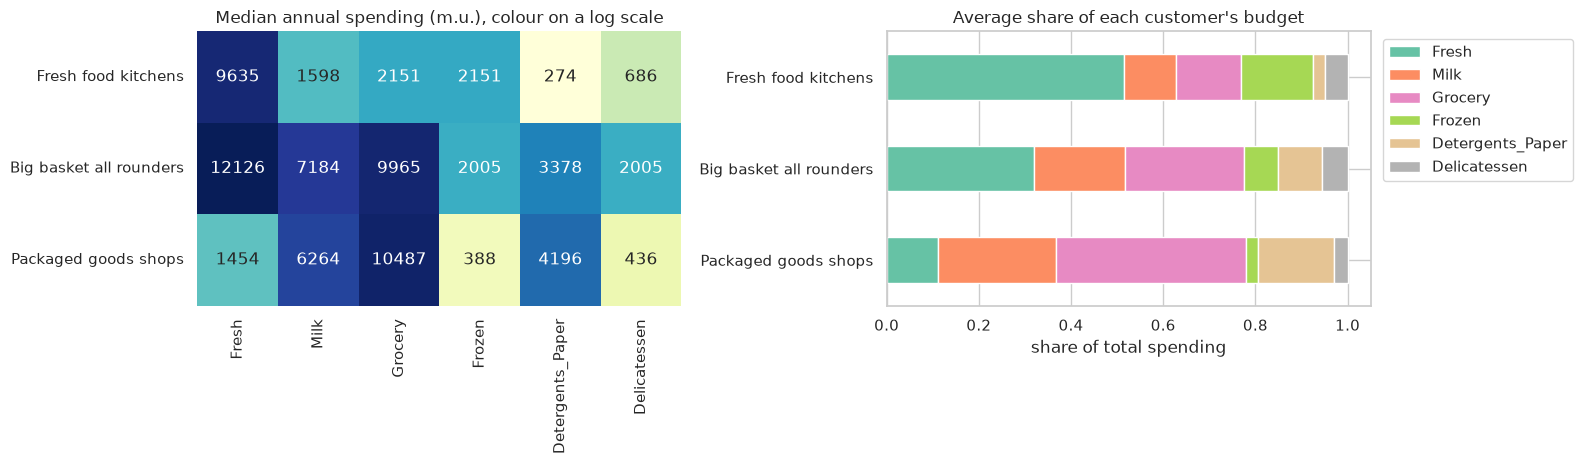

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
segment,,,,,,
Fresh food kitchens,0.514,0.113,0.140,0.157,0.026,0.049
Big basket all rounders,0.320,0.197,0.258,0.075,0.095,0.056
Packaged goods shops,0.111,0.256,0.412,0.027,0.165,0.029


In [29]:
# Showing how each segment splits its budget across categories (average share of each customer's total)
share = df[spend_cols].div(df[spend_cols].sum(axis=1), axis=0)
basket = share.groupby(df["segment"]).mean().loc[order]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.heatmap(np.log10(profile[spend_cols]), annot=profile[spend_cols].round(0), fmt=".0f", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set(title="Median annual spending (m.u.), colour on a log scale", ylabel="")
basket.plot.barh(stacked=True, ax=axes[1], colormap="Set2")
axes[1].set(title="Average share of each customer's budget", xlabel="share of total spending", ylabel="")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()
basket.round(3)

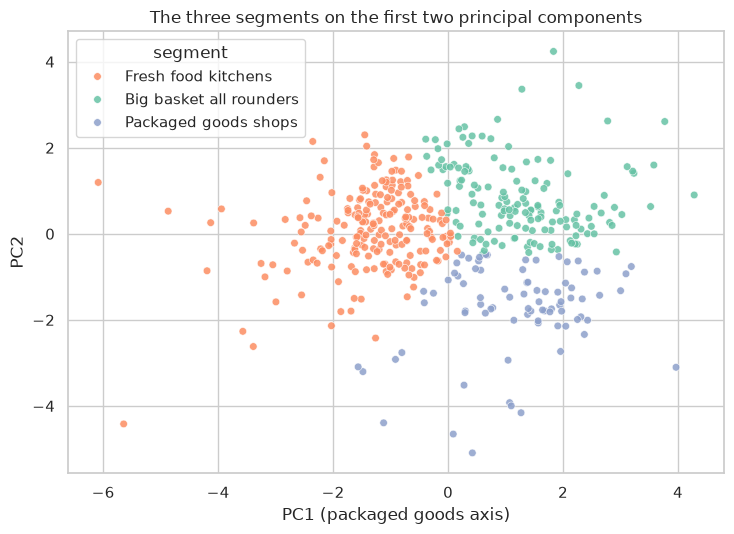

In [30]:
# Showing the segments on the principal component map used earlier
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["segment"], hue_order=order,
                palette=["#fc8d62", "#66c2a5", "#8da0cb"], s=30, alpha=0.85, ax=ax)
ax.set(xlabel="PC1 (packaged goods axis)", ylabel="PC2", title="The three segments on the first two principal components")
plt.tight_layout(); plt.show()

### 3.2 Names and spending habits

I am naming the segments after their spending pattern rather than after the channel, because the channel was not used to form them and each segment contains some of both channels.

Fresh food kitchens (212 customers, about half the base). This segment is almost entirely Horeca (99 percent). Its budget is dominated by fresh food, which takes about half of a typical customer's spending, followed by frozen goods (about 16 percent). It buys little grocery, milk or detergents, with a median of only 275 m.u. on detergents and paper, and it has the smallest accounts overall (median total about 18,500 m.u.). These look like restaurants and cafés that cook from fresh ingredients and source their packaged supplies elsewhere or in small quantities.

Big basket all rounders (147 customers, about a third). These are the largest accounts, with a median total of about 45,800 m.u., well over twice that of the kitchens. They buy substantial amounts in every category. They have the highest median spending on fresh food, milk and delicatessen, and they are close to the top in grocery, frozen goods and detergents. Their budget is the most balanced of the three, with about a third on fresh food and a quarter on grocery. Just over 60 percent are retailers, so this segment mixes grocery stores that also sell fresh produce with large hotels and catering businesses that buy a wide range.

Packaged goods shops (81 customers, about a fifth). These customers spend very little on fresh food (median under 1,500 m.u.) and concentrate on grocery, milk, and detergents and paper, which together make up over 80 percent of their budget. They have the highest median spending on grocery and on detergents and paper of any segment. Their delicatessen spending is also low. About 60 percent are retailers. This looks like small shops and minimarkets that stock shelf stable goods, plus some Horeca businesses that do not buy fresh food from this distributor.

At the broadest level, the distributor's customers fall into two robust groups, food service customers and packaged goods buyers. The cross table above shows that the two cluster food service group contains 211 of the 212 fresh food kitchens plus some of the smaller all rounders, while the packaged goods group contains most of the other two segments. The split within the packaged goods buyers is useful but less certain, as the sensitivity checks showed.

### 3.3 How the distributor could serve each segment

These suggestions follow from the spending patterns. They are hypotheses to test, for example with a pilot in one region, not proven effects.

Fresh food kitchens. Freshness and reliable delivery matter most here, so the distributor could offer frequent, early morning deliveries of fresh and frozen goods with a short order cut off. Because these customers spend little on packaged goods and cleaning supplies, there is room to cross sell: bundles of catering size grocery, detergents and paper alongside the fresh order, perhaps with a small discount for adding them to an existing delivery.

Big basket all rounders. These are the most valuable accounts and should be protected. A dedicated account manager, volume based pricing across all categories, and priority stock allocation make sense. They are also the strongest buyers of delicatessen, so new premium and specialty lines could be trialled with them first.

Packaged goods shops. These customers need dependable stock of shelf stable lines at good prices, so efficient bulk ordering (for example an online or phone reorder service with consolidated weekly deliveries) and promotions on grocery and detergent lines suit them. The low fresh spending is an opportunity, but a cautious one: some of these shops may lack refrigeration, so a small trial of a limited chilled range would show whether demand exists before investing.

Atypical customers. The customers flagged as noise by DBSCAN, and especially those with near zero spending in a category, are worth a quick review by the sales team. Some may be buying most of their needs from competitors, which makes them a retention or growth opportunity.

### 3.4 Limits of these segments

The cluster structure in this data is moderate, not strong (Hopkins about 0.80 against 0.73 for a structureless blob, and silhouette below 0.3). The segments are therefore best seen as useful summaries of a continuum. Customers near a boundary could reasonably belong to either neighbour. The two group split is robust to every check I ran, while the three group split moves when extreme customers are removed. The data covers one year of spending with this distributor only, so the segments say nothing about loyalty, profitability or what customers buy elsewhere. Before acting on them, the distributor should check them against margin and order frequency data and refresh them each year.

## References

Abreu, N. (2011). Análise do perfil do cliente Recheio e desenvolvimento de um sistema promocional. Master's dissertation in Marketing, ISCTE IUL, Lisbon. Data distributed through the UCI Machine Learning Repository (Wholesale customers data set).

Caliński, T. and Harabasz, J. (1974). A dendrite method for cluster analysis. Communications in Statistics, 3(1), 1 to 27.

Campello, R. J. G. B., Moulavi, D. and Sander, J. (2013). Density based clustering based on hierarchical density estimates. Advances in Knowledge Discovery and Data Mining (PAKDD), Lecture Notes in Computer Science 7819, 160 to 172.

Davies, D. L. and Bouldin, D. W. (1979). A cluster separation measure. IEEE Transactions on Pattern Analysis and Machine Intelligence, 1(2), 224 to 227.

Ester, M., Kriegel, H. P., Sander, J. and Xu, X. (1996). A density based algorithm for discovering clusters in large spatial databases with noise. Proceedings of the 2nd International Conference on Knowledge Discovery and Data Mining (KDD), 226 to 231.

Han, J., Kamber, M. and Pei, J. (2011). Data Mining: Concepts and Techniques (3rd edition). Morgan Kaufmann.

Hennig, C. (2007). Cluster wise assessment of cluster stability. Computational Statistics and Data Analysis, 52(1), 258 to 271.

Hopkins, B. and Skellam, J. G. (1954). A new method for determining the type of distribution of plant individuals. Annals of Botany, 18(2), 213 to 227.

Hubert, L. and Arabie, P. (1985). Comparing partitions. Journal of Classification, 2, 193 to 218.

Lawson, R. G. and Jurs, P. C. (1990). New index for clustering tendency and its application to chemical problems. Journal of Chemical Information and Computer Sciences, 30(1), 36 to 41.

MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability, 1, 281 to 297.

Pedregosa, F. and colleagues (2011). Scikit learn: machine learning in Python. Journal of Machine Learning Research, 12, 2825 to 2830.

Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53 to 65.

Sokal, R. R. and Rohlf, F. J. (1962). The comparison of dendrograms by objective methods. Taxon, 11(2), 33 to 40.

Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. Journal of the American Statistical Association, 58(301), 236 to 244.